RN pour classifier les 16 différents types d'images : 4 cercles, 4 diamants, 4 hexagones, 4 triangles

In [5]:
import os
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

Préparer les images

In [6]:
def process_dataset_pipeline(source_dir, output_dir):
    """
    Processes a nested dataset of images:
    1. Applies grayscale, bilateral filter, and Canny edge detection.
    2. Finds square contours to extract the Region of Interest (ROI).
    3. Normalizes ROI to 40x40, converts to grayscale, and applies a blur.
    4. Saves to output folder keeping original folder structure.
    """
    source_path = Path(source_dir)
    output_path = Path(output_dir)
    
    image_extensions = {'.jpg'}
    processed_records = []  # Stores (file_path, label) for visualization
    
    if not source_path.exists():
        print(f"Error: Source directory '{source_dir}' does not exist.")
        return processed_records

    print("Processing images...")
    
    for type_dir in source_path.iterdir():
        if not type_dir.is_dir():
            continue
            
        for subtype_dir in type_dir.iterdir():
            if not subtype_dir.is_dir():
                continue
            
            # Create destination folder structure
            dest_subtype_dir = output_path / type_dir.name / subtype_dir.name
            dest_subtype_dir.mkdir(parents=True, exist_ok=True)
            
            images = [f for f in subtype_dir.iterdir() if f.is_file() and f.suffix.lower() in image_extensions]
            
            for img_path in images:
                img = cv2.imread(str(img_path))
                if img is None:
                    continue
                
                # --- Step 1: Image Preparation ---
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                bilateral = cv2.bilateralFilter(gray, d=9, sigmaColor=75, sigmaSpace=75)
                edges = cv2.Canny(bilateral, 50, 150)
                
                # --- Step 2: ROI Extraction (Square contours) ---
                contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                
                best_roi = None
                max_area = 0
                
                for cnt in contours:
                    area = cv2.contourArea(cnt)
                    if area > 100:  # Minimum area threshold
                        perimeter = cv2.arcLength(cnt, True)
                        approx = cv2.approxPolyDP(cnt, 0.03 * perimeter, True)
                        
                        # Look for square/rectangular shapes (4 vertices)
                        if len(approx) == 4:
                            x, y, cw, ch = cv2.boundingRect(approx)
                            aspect_ratio = float(cw) / ch if ch > 0 else 0
                            
                            # Filter for roughly square aspect ratio
                            if 0.8 <= aspect_ratio <= 1.2 and area > max_area:
                                max_area = area
                                best_roi = img[y:y+ch, x:x+cw]
                
                # Fallback if no square contour is found
                if best_roi is None or best_roi.size == 0:
                    best_roi = img
                
                # --- Step 3: Extracted Region Preparation ---
                # 1. Resize/Normalize dimensions to 40 x 40
                roi_resized = cv2.resize(best_roi, (40, 40), interpolation=cv2.INTER_AREA)
                
                # 2. Convert to grayscale
                if len(roi_resized.shape) == 3:
                    roi_gray = cv2.cvtColor(roi_resized, cv2.COLOR_BGR2GRAY)
                else:
                    roi_gray = roi_resized
                    
                # 3. Apply blur to smooth details
                roi_blurred = cv2.GaussianBlur(roi_gray, (3, 3), 0)
                
                # Save processed image
                dest_file_path = dest_subtype_dir / img_path.name
                cv2.imwrite(str(dest_file_path), roi_blurred)
                
                # Keep record for visualization (label is the sub-folder name)
                processed_records.append((dest_file_path, subtype_dir.name))
                
    print(f"Pipeline complete! Processed {len(processed_records)} images.")
    return processed_records

In [7]:
SOURCE_DATASET = r"Ensemble_entrainement"
OUTPUT_DATASET = r"Ensemble_processed"

records = process_dataset_pipeline(SOURCE_DATASET, OUTPUT_DATASET)

Processing images...
Pipeline complete! Processed 3860 images.


Vérifier le pré-processing des images

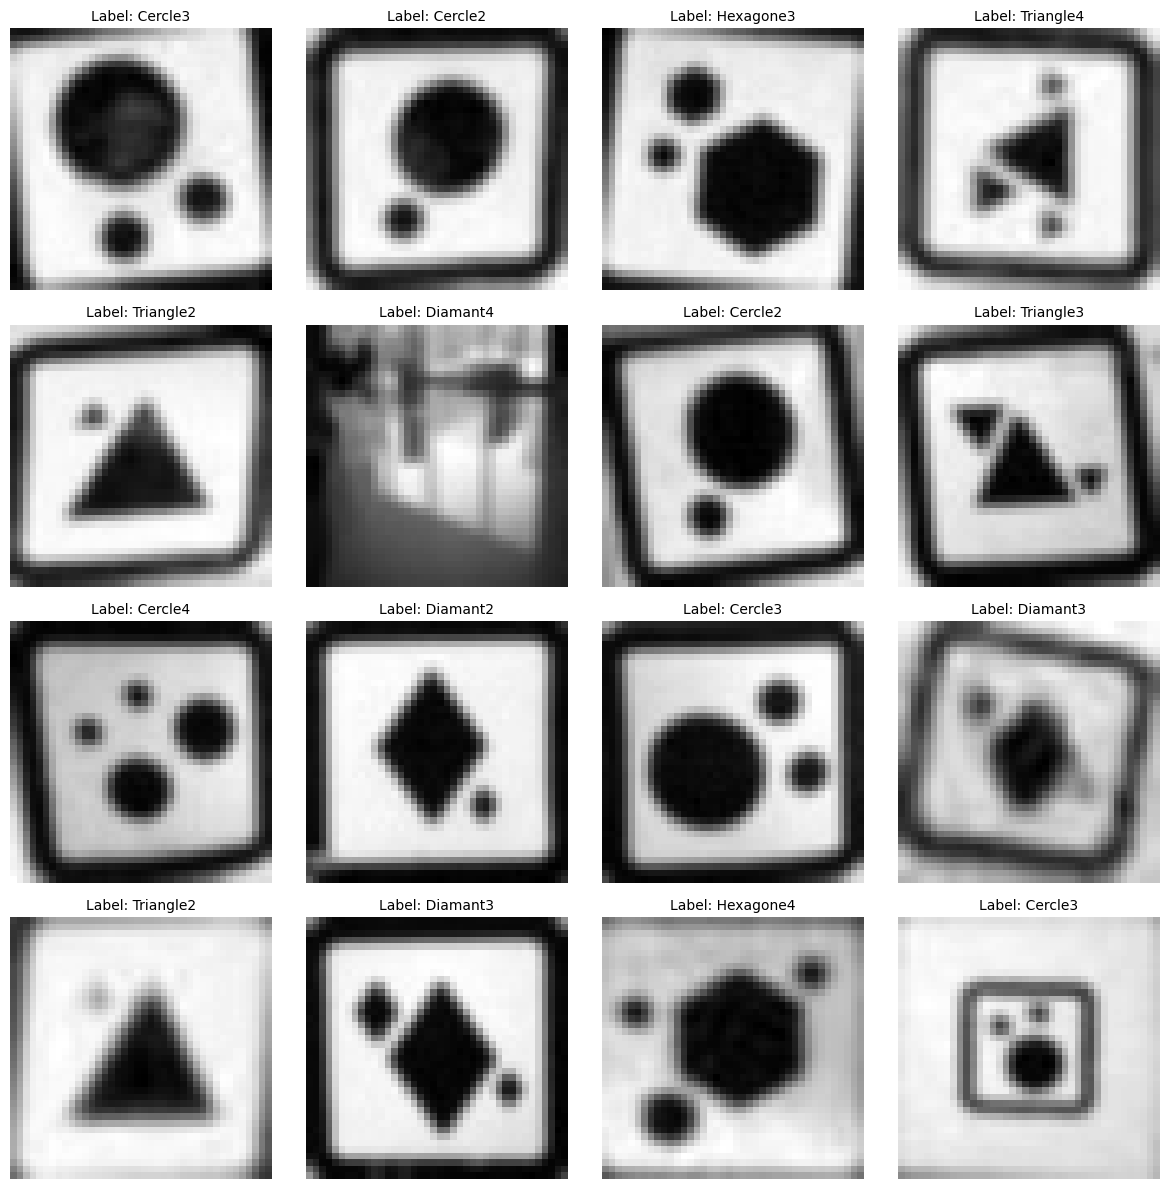

In [9]:
def plot_random_samples(processed_records, sample_size=16):
    """Picks 16 random processed images and displays them in a 4x4 grid with their labels."""
    if not processed_records:
        print("No processed records available to display.")
        return
        
    sample_size = min(16, len(processed_records))
    selected_samples = random.sample(processed_records, sample_size)
    
    plt.figure(figsize=(12, 12))
    for i, (img_path, label) in enumerate(selected_samples):
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        
        plt.subplot(4, 4, i + 1)
        plt.imshow(img, cmap='gray')
        plt.title(f"Label: {label}", fontsize=10)
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

# Run the visualization
plot_random_samples(records, sample_size=16)

Augmenter les image pour enrichir notre dataset

In [ ]:
##Not for now, a implémenter plus tard

On va essayer de classifier les 16 types selon deux caractéristiques principales :

- Forme
- Nombre de formes dans l'image

On va donc avoir les résultats possibles suivants:

| Type | Binaire |
| :--- | :--- |
| Cercle2 | 0000 |
| Cercle3 | 0001 |
| Cercle4 | 0010 |
| Cercle5 | 0011 |
| Diamant2 | 0100 |
| Diamant3 | 0101 |
| Diamant4 | 0110 |
| Diamant5 | 0111 |
| Hexagone2 | 1000 |
| Hexagone3 | 1001 |
| Hexagone4 | 1010 |
| Hexagone5 | 1011 |
| Triangle2 | 1100 |
| Triangle3 | 1101 |
| Triangle4 | 1110 |
| Triangle5 | 1111 |

In [12]:
#À partir des jpgs, convertir les images en matrices de pixels, et associer leur label dans une matrice de labels
LABELS = {
    "Cercle2": "0000", "Cercle3": "0001", "Cercle4": "0010", "Cercle5": "0011",
    "Diamant2": "0100", "Diamant3": "0101", "Diamant4": "0110", "Diamant5": "0111",
    "Hexagone2": "1000", "Hexagone3": "1001", "Hexagone4": "1010", "Hexagone5": "1011",
    "Triangle2": "1100", "Triangle3": "1101", "Triangle4": "1110", "Triangle5": "1111",
}

def load_dataset(records):
    """Retourne X (N,40,40) normalisé [0,1], y (N,4) bits, classes (N,) index 0-15."""
    X, y, classes = [], [], []
    for img_path, folder in records:
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        X.append(img.astype(np.float32) / 255.0)
        y.append([int(b) for b in LABELS[folder]])
        classes.append(int(LABELS[folder], 2))
    return np.array(X), np.array(y, dtype=np.uint8), np.array(classes)

def stratified_k_folds(classes, k=4, seed=42):
    """Sépare les indices en k sous-ensembles avec la même proportion de chaque classe."""
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for c in np.unique(classes):
        idx = rng.permutation(np.where(classes == c)[0])
        for i, part in enumerate(np.array_split(idx, k)):
            folds[i].extend(part.tolist())
    return [np.array(sorted(f)) for f in folds]

# Ensemble d'entraînement (même pré-traitement que ci-dessus)
X_train, y_train, train_classes = load_dataset(records)

# Ensemble B (test) : même pré-traitement que l'entraînement
records_B = process_dataset_pipeline(r"EnsembleB", r"EnsembleB_processed")
X_test, y_test, test_classes = load_dataset(records_B)

# Validation croisée à 4 sous-ensembles
folds = stratified_k_folds(train_classes, k=4)
cv_splits = [(np.concatenate([folds[j] for j in range(4) if j != i]), folds[i]) for i in range(4)]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)
print("Taille des folds:", [len(f) for f in folds])

splits = [("train", train_classes)] + [(f"fold{i}", train_classes[f]) for i, f in enumerate(folds)] + [("test ", test_classes)]

# En-tête du tableau
header = "| Split | " + " | ".join([f"C{i}" for i in range(16)]) + " |"
separator = "| :--- | " + " | ".join([":---:" for _ in range(16)]) + " |"

print(header)
print(separator)

for name, arr in splits:
    props = np.round(np.bincount(arr, minlength=16) / len(arr), 3)
    row_str = " | ".join([f"{p:.3f}" for p in props])
    print(f"| {name} | {row_str} |")


Processing images...
Pipeline complete! Processed 964 images.
X_train: (3860, 40, 40) y_train: (3860, 4)
X_test: (964, 40, 40) y_test: (964, 4)
Taille des folds: [972, 969, 962, 957]
| Split | C0 | C1 | C2 | C3 | C4 | C5 | C6 | C7 | C8 | C9 | C10 | C11 | C12 | C13 | C14 | C15 |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| train | 0.065 | 0.115 | 0.072 | 0.044 | 0.092 | 0.069 | 0.052 | 0.042 | 0.070 | 0.057 | 0.049 | 0.056 | 0.092 | 0.044 | 0.049 | 0.031 |
| fold0 | 0.065 | 0.114 | 0.072 | 0.044 | 0.092 | 0.069 | 0.052 | 0.042 | 0.070 | 0.058 | 0.049 | 0.057 | 0.092 | 0.044 | 0.049 | 0.031 |
| fold1 | 0.064 | 0.115 | 0.072 | 0.044 | 0.092 | 0.069 | 0.053 | 0.042 | 0.070 | 0.057 | 0.050 | 0.056 | 0.092 | 0.044 | 0.050 | 0.031 |
| fold2 | 0.064 | 0.115 | 0.072 | 0.044 | 0.093 | 0.069 | 0.052 | 0.042 | 0.071 | 0.057 | 0.050 | 0.056 | 0.091 | 0.045 | 0.049 | 0.031 |
| fold3 | 0.065 | 0.116 | 0.072 

Étape 4 — Extraction des caractéristiques

Chaque ROI est déjà une image en niveaux de gris de 40×40, avec des pixels normalisés entre 0 et 1. On utilise directement ces pixels comme caractéristiques en aplatissant chaque image en un vecteur de 1 600 valeurs.

In [ ]:
def extract_pixel_features(images):
    images = np.asarray(images, dtype=np.float32)
    if images.ndim != 3:
        raise ValueError(f"images doit avoir la forme (N, hauteur, largeur), reçu {images.shape}")
    return images.reshape(images.shape[0], images.shape[1] * images.shape[2])

X_train_features = extract_pixel_features(X_train)
X_test_features = extract_pixel_features(X_test)

print("X_train_features:", X_train_features.shape)
print("X_test_features:", X_test_features.shape)

Fonction d'activation couches cachées : ReLU

Fonction d'activation couche de sortie : SoftMax

Fonction de coût : multiclass cross entropy

On fait cross validation à 4 folds